In [7]:
!pip install yfinance pandas

In [12]:
!pip install feedparser

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 4.3 MB/s eta 0:00:00


In [2]:
 !pip install requests beautifulsoup4 pandas

In [4]:
# Cell 1: 匯入與安裝必要套件
import requests
from bs4 import BeautifulSoup  # 修正此處，移除多餘的亂碼
import pandas as pd
from datetime import datetime
import time
import json

print("套件載入成功！")

套件載入成功！


In [25]:
import requests
import pandas as pd
from datetime import datetime, timedelta
import time

TARGET_STOCKS = {
    '2330': '台積電',
    '2317': '鴻海',
    '2603': '長榮',
    '2002': '中鋼',
    '2891': '中信金',
}

def fetch_cnyes_daily(target_date):
    """抓取單一「特定日期」的所有台股大盤新聞"""
    url = 'https://api.cnyes.com/media/api/v1/newslist/category/tw_stock'
    headers = {'User-Agent': 'Mozilla/5.0'}

    # 設定當天的 00:00:00 到 23:59:59
    start_ts = int(target_date.timestamp())
    end_ts = int((target_date + timedelta(days=1, seconds=-1)).timestamp())

    daily_news = []

    # 每天的新聞通常不會超過 10 頁 (300筆)，完美避開 900 筆的 422 限制
    for page in range(1, 15):
        params = {'limit': 30, 'page': page, 'startAt': start_ts, 'endAt': end_ts}
        try:
            res = requests.get(url, headers=headers, params=params, timeout=10)
            if res.status_code != 200: break

            data = res.json()
            items = data.get('items', {}).get('data', [])
            if not items: break

            for item in items:
                daily_news.append({
                    'news_id': item.get('newsId'),
                    'publish_time': datetime.fromtimestamp(item.get('publishAt')).strftime('%Y-%m-%d %H:%M:%S'),
                    'title': str(item.get('title') or '').strip(),
                    'summary': str(item.get('summary') or '').strip(),
                })
            time.sleep(0.3)
        except:
            break
    return daily_news

def main():
    start_date = datetime(2026, 1, 1)
    end_date = datetime(2026, 10, 11)

    print(f"🚀 啟動逐日切塊爬蟲！區間：{start_date.date()} 至 {end_date.date()}")

    all_filtered_news = []
    current_date = start_date

    # 逐日推進
    while current_date <= end_date:
        print(f"正在抓取 {current_date.date()} 的資料...", end="\r")
        daily_news = fetch_cnyes_daily(current_date)

        # 在本地端進行嚴格的關鍵字過濾
        for news in daily_news:
            for code, name in TARGET_STOCKS.items():
                # 如果標題或內文包含公司名稱或代號
                if name in news['title'] or code in news['title'] or name in news['summary']:
                    filtered_item = news.copy()
                    filtered_item['stock_name'] = name
                    filtered_item['ticker'] = code
                    all_filtered_news.append(filtered_item)

        current_date += timedelta(days=1)
        time.sleep(0.5) # 避免 API 封鎖

    print("\n🎉 抓取與過濾完成！")

    if all_filtered_news:
        df = pd.DataFrame(all_filtered_news)
        df = df.drop_duplicates(subset=['news_id', 'stock_name']).sort_values('publish_time').reset_index(drop=True)

        # 整理最終輸出的欄位
        df = df[['stock_name', 'ticker', 'publish_time', 'title', 'summary']]

        output_file = 'tw_5stocks_news_2026.csv'
        df.to_csv(output_file, index=False, encoding='utf-8-sig')
        print(f"總共獲得 {len(df)} 筆專屬這五檔個股的精準歷史新聞，存檔至 {output_file}")
        print(df.head())
    else:
        print("沒有找到符合條件的資料。")

if __name__ == "__main__":
    main()

🚀 啟動逐日切塊爬蟲！區間：2026-01-01 至 2026-10-11

🎉 抓取與過濾完成！
總共獲得 1713 筆專屬這五檔個股的精準歷史新聞，存檔至 tw_5stocks_news_2026.csv
  stock_name ticker         publish_time  \
0        台積電   2330  2025-12-31 20:30:13   
1        台積電   2330  2026-01-01 04:31:17   
2        台積電   2330  2026-01-01 05:00:07   
3        台積電   2330  2026-01-01 07:40:04   
4        台積電   2330  2026-01-01 21:10:04   

                                     title  \
0                中企H200搶購戰開打 輝達庫存告急緊急求援台積電   
1               美方有意放行 中企大量採購輝達H200 台積電迎急單   
2  美國放行！台積電(2330)南京廠獲准輸入美製晶片設備確保2026營運不受影響   
3        美國向台積電核發出口許可！南京廠可持續進口設備、中國產線運作不中斷   
4   〈台股盤前要聞〉新年開局再拚2萬9、台積電迎輝達急單、大立光1/8法說打前鋒   

                                             summary  
0  綜合外電周三 (31 日) 報導，面對中國科技公司對 H200 晶片的強勁需求，輝達 (NV...  
1  隨著美國商務部有意放行輝達 (NVDA-US) 的 H200 晶片銷往中國，據路透報導，中國...  
2                                                     
3  美國政府核發年度出口許可，允許台積電持續向中國南京廠進口美國晶片製造設備。台積電表示，此舉可...  
4                                             台股盤前要聞  


In [26]:
# Cell: NLP 情緒量化與防前視偏誤時間軸對齊
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
# 若要用正式 FinBERT，可改用 Hugging Face transformers，此處先以快速原型示範情緒極性轉換邏輯
try:
    from snownlp import SnowNLP
except ImportError:
    !pip install snownlp
    from snownlp import SnowNLP

# 1. 讀取我們剛剛爬好的歷史新聞
print("📥 載入歷史新聞資料集...")
df_news = pd.read_csv('tw_5stocks_news_2026.csv')
df_news['publish_time'] = pd.to_datetime(df_news['publish_time'])

def analyze_sentiment(text):
    """
    計算情緒分數，將結果映射至 [-1, 1]
    (未來可在此抽換為 Hugging Face 的 FinBERT-Chinese 模型預測邏輯)
    """
    try:
        s = SnowNLP(text)
        # SnowNLP 輸出為 [0, 1] 的正面機率，我們將其平移至 [-1, 1] 區間
        score = (s.sentiments * 2) - 1
        return round(score, 4)
    except:
        return 0.0

# 2. 合併標題與摘要進行 NLP 打分
print("🧠 進行 NLP 情緒量化打分 (這可能會花一兩分鐘)...")
df_news['content_to_score'] = df_news['title'] + " " + df_news['summary'].fillna("")
df_news['sentiment_score'] = df_news['content_to_score'].apply(analyze_sentiment)

# 3. 實作「13:30 收盤切分」防前視偏誤機制
def align_trading_date(publish_time):
    """
    若發布時間在 13:30 之後，則將其情緒影響力遞延至下一個日曆日
    (後續與交易日曆 Merge 時會自動對齊至最近的開盤日)
    """
    if publish_time.time() > datetime.strptime('13:30:00', '%H:%M:%S').time():
        return (publish_time + timedelta(days=1)).date()
    return publish_time.date()

print("⏱️ 執行 13:30 防前視偏誤時間切分...")
df_news['aligned_date'] = df_news['publish_time'].apply(align_trading_date)

# 4. 聚合為每日情緒特徵 (若同日有多則新聞，取平均分數)
print("📊 產出每日股票情緒特徵矩陣...")
daily_sentiment = df_news.groupby(['ticker', 'stock_name', 'aligned_date'])['sentiment_score'].mean().reset_index()
daily_sentiment = daily_sentiment.rename(columns={'aligned_date': 'Date', 'sentiment_score': 'Daily_Sentiment'})

# 將代碼補上 .TW 以利後續與 yfinance 股價對齊
daily_sentiment['ticker'] = daily_sentiment['ticker'].astype(str) + '.TW'

print(f"\n🎉 成功產出 {len(daily_sentiment)} 筆每日對齊特徵！")
print("\n特徵矩陣預覽：")
display(daily_sentiment.head(10))

# 儲存特徵矩陣供 LSTM 模型使用
output_feature_file = 'sentiment_features_2026.csv'
daily_sentiment.to_csv(output_feature_file, index=False)
print(f"已儲存特徵矩陣至 {output_feature_file}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.6/37.6 MB 25.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for snownlp: filename=snownlp-0.12.3-py3-none-any.whl size=37761000 sha256=cb36e10349ff24cdf82588035194b9000d377b4989b6a2fd70eed29a34541042
  Stored in directory: /root/.cache/pip/wheels/97/c8/eb/fe9c4a8c871e637d941aac64f1a4c6440876a807aa35f34f58
Successfully built snownlp
📥 載入歷史新聞資料集...
🧠 進行 NLP 情緒量化打分 (這可能會花一兩分鐘)...
⏱️ 執行 13:30 防前視偏誤時間切分...
📊 產出每日股票情緒特徵矩陣...

🎉 成功產出 596 筆每日對齊特徵！

特徵矩陣預覽：


,ticker,stock_name,Date,Daily_Sentiment
0,2002.TW,中鋼,2026-01-07,-1.0000
1,2002.TW,中鋼,2026-01-12,-0.3776
2,2002.TW,中鋼,2026-01-23,-0.9799
3,2002.TW,中鋼,2026-01-26,-1.0000
4,2002.TW,中鋼,2026-01-28,0.8412
5,2002.TW,中鋼,2026-01-29,-1.0000
6,2002.TW,中鋼,2026-01-30,-1.0000
7,2002.TW,中鋼,2026-02-02,-1.0000
8,2002.TW,中鋼,2026-02-03,-1.0000
9,2002.TW,中鋼,2026-02-10,0.9526


已儲存特徵矩陣至 sentiment_features_2026.csv


In [28]:
# Cell: 股價、大盤波動率與情緒特徵的多變量融合
import yfinance as yf
import pandas as pd
import numpy as np

print("📥 1. 讀取情緒特徵矩陣...")
df_sent = pd.read_csv('sentiment_features_2026.csv')
df_sent['Date'] = pd.to_datetime(df_sent['Date']).dt.date

# 定義標的與抓取區間 (起始時間提早兩個月，為了讓前期的 MA20、MACD 算得出數值)
tickers = ['2330.TW', '2317.TW', '2603.TW', '2002.TW', '2891.TW']
start_date = '2025-10-15'
end_date = '2026-10-15'

print("📈 2. 下載個股歷史股價並計算技術指標 (MA, RSI, MACD)...")
df_all_stocks = pd.DataFrame()

for ticker in tickers:
    df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)
    if isinstance(df_price.columns, pd.MultiIndex):
        df_price.columns = df_price.columns.get_level_values(0)

    df_price = df_price.dropna(subset=['Close']).copy()
    df_price['ticker'] = ticker

    # 計算日報酬率
    # 避免未來 Pandas 版本警告，加入 fill_method=None
    df_price['Daily_Return'] = df_price['Close'].pct_change(fill_method=None) * 100
    df_price['Target_Next_Return'] = df_price['Daily_Return'].shift(-1) # LSTM 的預測目標 Y

    # 計算技術指標
    df_price['MA5'] = df_price['Close'].rolling(window=5).mean()
    df_price['MA20'] = df_price['Close'].rolling(window=20).mean()

    # 計算 RSI (14)
    delta = df_price['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss.replace(0, np.nan)
    df_price['RSI_14'] = 100 - (100 / (1 + rs))

    # 計算 MACD
    ema12 = df_price['Close'].ewm(span=12, adjust=False).mean()
    ema26 = df_price['Close'].ewm(span=26, adjust=False).mean()
    df_price['MACD'] = ema12 - ema26
    df_price['MACD_Signal'] = df_price['MACD'].ewm(span=9, adjust=False).mean()
    df_price['MACD_Hist'] = df_price['MACD'] - df_price['MACD_Signal']

    df_price = df_price.reset_index()
    df_price['Date'] = pd.to_datetime(df_price['Date']).dt.date
    df_all_stocks = pd.concat([df_all_stocks, df_price], ignore_index=True)

print("🌪️ 3. 下載大盤指數 (^TWII) 並計算 20 天滾動歷史波動率做為風控濾網...")
df_twii = yf.download('^TWII', start=start_date, end=end_date, progress=False)
if isinstance(df_twii.columns, pd.MultiIndex):
    df_twii.columns = df_twii.columns.get_level_values(0)

df_twii = df_twii.dropna(subset=['Close']).copy()
df_twii['TWII_Return'] = df_twii['Close'].pct_change(fill_method=None)
# 計算 20 天滾動年化波動率 (Market Risk)
df_twii['Market_Vol_20d'] = df_twii['TWII_Return'].rolling(window=20).std() * np.sqrt(252) * 100
df_twii = df_twii.reset_index()
df_twii['Date'] = pd.to_datetime(df_twii['Date']).dt.date

# 擷取需要的大盤風控欄位
df_market_risk = df_twii[['Date', 'Market_Vol_20d']].copy()

print("🔗 4. 進行多變量特徵融合 (Merge)...")
# 4a. 股價特徵合併大盤波動率
df_merged = pd.merge(df_all_stocks, df_market_risk, on='Date', how='left')

# 4b. 合併新聞情緒分數 (改用單行防呆寫法避免 Jupyter 斷行解析錯誤)
df_final = pd.merge(df_merged, df_sent[['Date', 'ticker', 'Daily_Sentiment']], on=['Date', 'ticker'], how='left')

# 填補沒有新聞的日子 (情緒設為 0 中立)
df_final['Daily_Sentiment'] = df_final['Daily_Sentiment'].fillna(0.0)

# 清理因為計算均線而產生的 NaN
df_final = df_final.dropna(subset=['MA20', 'RSI_14', 'MACD_Hist', 'Market_Vol_20d', 'Target_Next_Return'])

print(f"🎉 最終多變量特徵資料集準備完成！共 {len(df_final)} 筆訓練樣本。")
print("\n最終資料預覽 (特徵將直接餵給 LSTM)：")
display(df_final[['Date', 'ticker', 'Close', 'MA20', 'RSI_14', 'MACD_Hist', 'Market_Vol_20d', 'Daily_Sentiment', 'Target_Next_Return']].head())

# 儲存最終給 LSTM 訓練用的特徵表
output_lstm_file = 'lstm_multivariate_features_2026.csv'
df_final.to_csv(output_lstm_file, index=False)
print(f"已儲存 LSTM 訓練用資料集至 {output_lstm_file}")

📥 1. 讀取情緒特徵矩陣...
📈 2. 下載個股歷史股價並計算技術指標 (MA, RSI, MACD)...


/tmp/ipykernel_453/2941848558.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_453/2941848558.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_453/2941848558.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_453/2941848558.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)
/tmp/ipykernel_453/2941848558.py:19: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_price = yf.download(ticker, start=start_date, end=end_date, progress=False)


🌪️ 3. 下載大盤指數 (^TWII) 並計算 20 天滾動歷史波動率做為風控濾網...


/tmp/ipykernel_453/2941848558.py:54: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df_twii = yf.download('^TWII', start=start_date, end=end_date, progress=False)


🔗 4. 進行多變量特徵融合 (Merge)...
🎉 最終多變量特徵資料集準備完成！共 1090 筆訓練樣本。

最終資料預覽 (特徵將直接餵給 LSTM)：


,Date,ticker,Close,MA20,RSI_14,MACD_Hist,Market_Vol_20d,Daily_Sentiment,Target_Next_Return
20,2025-11-13,2330.TW,1442.312500,1459.353528,52.631589,-2.908696,14.086250,0.0,-2.054806
21,2025-11-14,2330.TW,1412.675781,1456.636835,36.842095,-5.035258,14.851614,0.0,1.048957
22,2025-11-17,2330.TW,1427.494141,1456.389862,42.499981,-5.169789,14.160045,0.0,-2.768164
23,2025-11-18,2330.TW,1387.978760,1452.685291,26.190538,-7.504372,15.841975,0.0,-0.711739
24,2025-11-19,2330.TW,1378.099976,1448.486780,25.000070,-9.187079,15.860648,0.0,4.301081


已儲存 LSTM 訓練用資料集至 lstm_multivariate_features_2026.csv


📥 正在為 Colab 環境下載中文字體，請稍候...
📊 新聞情緒對隔日報酬率之影響：


,平均隔日報酬率_百分比,發生天數_次數,報酬率波動_標準差
Sentiment_Label,,,
中立 (Neutral),0.124,646,1.851
偏多 (Positive),0.363,47,2.511
偏空 (Negative),0.165,397,2.037


/tmp/ipykernel_453/3163840300.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


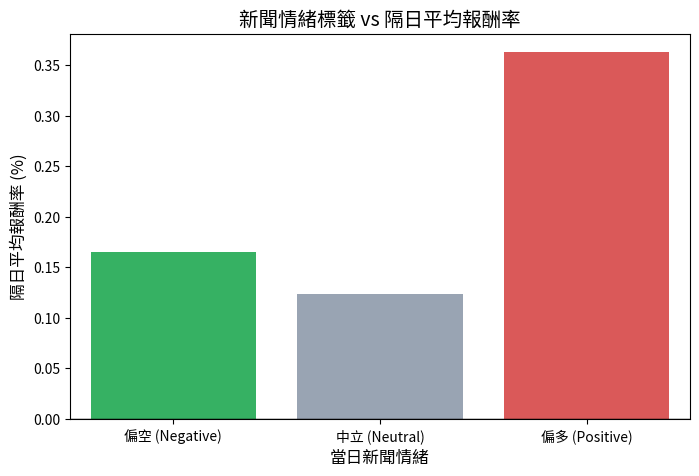

In [31]:
# Cell: 探索性資料分析 (EDA) - 新聞情緒對隔日報酬率的影響 (Google Colab 終極解法)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import urllib.request
import os

# 1. 自動下載開源繁體中文字體 (Noto Sans CJK TC) 解決 Colab 亂碼問題
font_url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
font_path = "NotoSansCJKtc-Regular.otf"

if not os.path.exists(font_path):
    print("📥 正在為 Colab 環境下載中文字體，請稍候...")
    urllib.request.urlretrieve(font_url, font_path)

# 2. 註冊並強制套用該中文字體
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams['font.sans-serif'] = [font_prop.get_name()]
plt.rcParams['axes.unicode_minus'] = False

# 3. 讀取特徵大表
try:
    df_eda = pd.read_csv('lstm_multivariate_features_2026.csv')

    # 4. 定義情緒標籤函式
    def get_sentiment_label(score):
        if score > 0.2: return '偏多 (Positive)'
        elif score < -0.2: return '偏空 (Negative)'
        else: return '中立 (Neutral)'

    df_eda['Sentiment_Label'] = df_eda['Daily_Sentiment'].apply(get_sentiment_label)

    # 5. 統計不同情緒下的隔日平均報酬率與發生次數
    impact_stats = df_eda.groupby('Sentiment_Label')['Target_Next_Return'].agg(
        平均隔日報酬率_百分比='mean',
        發生天數_次數='count',
        報酬率波動_標準差='std'
    ).round(3)

    print("📊 新聞情緒對隔日報酬率之影響：")
    display(impact_stats)

    # 6. 繪製視覺化圖表
    plt.figure(figsize=(8, 5))
    colors = {'偏多 (Positive)': '#ef4444', '中立 (Neutral)': '#94a3b8', '偏空 (Negative)': '#22c55e'}
    sns.barplot(
        x=impact_stats.index,
        y=impact_stats['平均隔日報酬率_百分比'],
        palette=colors,
        order=['偏空 (Negative)', '中立 (Neutral)', '偏多 (Positive)']
    )

    plt.title('新聞情緒標籤 vs 隔日平均報酬率', fontsize=14, fontweight='bold')
    plt.ylabel('隔日平均報酬率 (%)', fontsize=12)
    plt.xlabel('當日新聞情緒', fontsize=12)
    plt.axhline(0, color='black', linewidth=1)
    plt.show()

except FileNotFoundError:
    print("❌ 找不到 lstm_multivariate_features_2026.csv，請確認前面的特徵對齊步驟是否已執行完畢。")